# Adiabatic QeMCMC

Here we introduce an approach to QeMCMC which includes an "adiabatic dressing". See [Adiabatic dressing of quantum enhanced Markov chains](https://arxiv.org/pdf/2603.28076) for the details.

The basic idea of their approach is to change the time evolution that we implement on the quantum computer from a "quench" (time evolution under a time independent hamiltonian of the form $H = H_\text{prob} + \gamma H_\text{mix}$) to an evolution under a time dependent Hamiltonian, $H = H_\text{prob} + \gamma (t) H_\text{mix}$ where $\gamma (0) = 0$ = \gamma (t_\text{max})$. For well behaved functions and for large $t$, this should return the system to the same basis state that you start in thanks to the adiabatic theorem. However for shorter times, one will see diabatic transitions, out of the ground state towards nearby energy levels - exactly what we want in QeMCMC.


## Imports

In [2]:
from joblib import Parallel, delayed
from matplotlib import pyplot as plt

# This helps you build an example Ising model
from qemcmc.model import ModelMaker

# Internal imports from QeMCMC package
# sampler contains the classical and quantum enhanced MCMC sampler
from qemcmc.sampler import ClassicalProposal, AdiabaticProposal
from qemcmc.sampler.runners import MCMCRunner

# These are object useful to store the results of the MCMC simulation
from qemcmc.utils import plot_chains



## Define model problem and algorithm parameters

In [16]:

# Define parameters
n = 5 # Number of spins in the system
reps = 5 # How many markov chains to produce
steps = 300 # Length of each markov chain
temp = 0.1 # Temperature of the system


# QeMCMC parameters
gamma = 2# Relative strength of mixer hamiltonian 
alpha = 2 # Time for adiabatic ramp
kappa = 3 # time for plateaux
# Build an Ising model to test the algorithms on
model_type = "Fully Connected Ising"
name = "Test Ising model"
model = ModelMaker(n, model_type, name).model
initial_states = model.initial_state


## Run classical MCMC

In [17]:

runner = MCMCRunner(model, temp)


# Run classical (uniform and local) chains

uni_chains = []
for rep in range(reps):
    classical_uniform_proposal = ClassicalProposal(model=model, method = "uniform")
    uni_chain = runner.run(classical_uniform_proposal, steps, initial_state = initial_states[rep], name = "classical uniform MCMC", verbose = False, sample_frequency = 1)
    uni_chains.append(uni_chain)


loc_chains = []
for rep in range(reps):
    classical_local_proposal = ClassicalProposal(model=model, method = "local")
    loc_chain = runner.run(classical_local_proposal, steps, initial_state = initial_states[rep], name = "classical local MCMC", verbose = False, sample_frequency = 1)
    loc_chains.append(loc_chain)




## Run adiabatic MCMC

In [18]:
qsteps = 100
def run_qemcmc(rep):
    quantum_proposal = AdiabaticProposal(model, gamma=gamma, alpha=alpha, kappa = kappa, delta_t = 0.3)
    return runner.run(quantum_proposal, qsteps, initial_state=initial_states[rep], name="QeMCMC", verbose=True, sample_frequency=1)

# Run in parallel as they can take a while.
adi_chains = Parallel(n_jobs=-1)(delayed(run_qemcmc)(rep) for rep in range(reps))

#adi_chains = [run_qemcmc(1)]
    

## Analysis

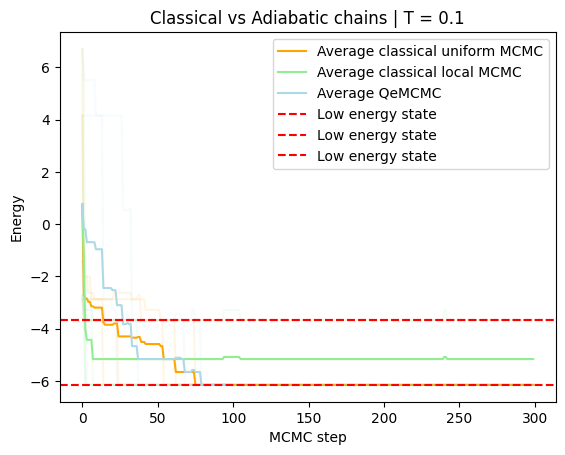

In [19]:
# Plot the list of chains with a helper function
# Dark line is for average ove rchains, transparent lines are for each individual chains

plot_chains(uni_chains, "orange", "classical uniform MCMC")
plot_chains(loc_chains, "lightgreen", "classical local MCMC")
plot_chains(adi_chains, "lightblue", "QeMCMC")

lowest_energies, degeneracies, lowest_configs = model.get_lowest_energies(3, return_configurations=True)
for i, energy in enumerate(lowest_energies):
    if i<3:
        plt.axhline(energy, color="red", linestyle="--", label=f"Low energy state")

plt.xlabel("MCMC step")
plt.ylabel("Energy")
plt.title("Classical vs Adiabatic chains | T = {}".format(temp))
plt.legend()
plt.show()

In [5]:
from joblib import Parallel, delayed
from matplotlib import pyplot as plt

# This helps you build an example Ising model
from qemcmc.model import ModelMaker

# Internal imports from QeMCMC package
# sampler contains the classical and quantum enhanced MCMC sampler
from qemcmc.sampler import ClassicalProposal, AdiabaticProposal
from qemcmc.sampler.runners import MCMCRunner

# These are object useful to store the results of the MCMC simulation
from qemcmc.utils import plot_chains

from qemcmc.spectralgap import SpectralGap
import numpy as np

In [ ]:

# Define parameters
n = 5 # Number of spins in the system
reps = 5 # How many markov chains to produce
steps = 300 # Length of each markov chain
temp = 0.1 # Temperature of the system


# QeMCMC parameters
gamma = 2# Relative strength of mixer hamiltonian 
alpha = 2 # Time for adiabatic ramp
kappa = 3 # time for plateaux
# Build an Ising model to test the algorithms on
model_type = "Fully Connected Ising"
name = "Test Ising model"
model = ModelMaker(n, model_type, name).model
initial_states = model.initial_state
alphas = np.arange(0,5,0.1)
print(alphas)
gaps =[]
for alpha in alphas:
    quantum_proposal = AdiabaticProposal(model, gamma=gamma, alpha=alpha, kappa = kappa, delta_t = 0.3)
    sg = SpectralGap(quantum_proposal, model, temp)
    gap = sg.find_spectral_gap()
    gaps.append(gap)
print(gap)